# Teste de imagens próprias — Detector Fase 2 (ViT + FFT + EfficientNet com gate)

Notebook **independente**: usa só o `phase2_final.pt` salvo no Drive. Não baixa datasets nem retreina.

1. Rode as células em ordem (GPU recomendada, mas funciona em CPU, só mais lento).
2. Defina `CKPT_PATH` na célula 3.
3. Use a célula 6 para imagens avulsas ou a célula 7 para avaliar uma pasta rotulada (`real/` e `fake/`).

**Limites:** o modelo foi treinado em rostos (reais do Flickr × falsos de StyleGAN) mais COCO como "real". Resultado em outros tipos de imagem ou geradores é indicativo, não validação.

In [8]:
# Imports mínimos para inferência
import os, csv, math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from PIL import Image
from sklearn.metrics import confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt

# Usa GPU se houver; senão CPU (a inferência funciona nos dois)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

Dispositivo: cuda


In [9]:
# Localização do checkpoint final salvo pelo notebook de treino
from google.colab import drive
drive.mount("/content/drive")

CKPT_PATH = "/content/drive/MyDrive/TCC_Final/modelos/fase2_gate_vit_fft_cnn/phase2_final.pt"

# Se o arquivo não estiver no Drive, abre o seletor para enviar o phase2_final.pt direto
if not os.path.isfile(CKPT_PATH):
    from google.colab import files as colab_files
    print("Checkpoint não encontrado no Drive. Envie o phase2_final.pt:")
    up = colab_files.upload()
    CKPT_PATH = next(iter(up))          # nome do arquivo enviado (fica em /content)
print("Usando:", CKPT_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Usando: /content/drive/MyDrive/TCC_Final/modelos/fase2_gate_vit_fft_cnn/phase2_final.pt


In [10]:
# Definições EXATAS da arquitetura (copiadas do notebook de treino; os nomes dos módulos
# precisam ser idênticos aos do checkpoint, senão o load_state_dict falha).
# ---------- Componentes da Fase 1 (NÃO alterar: precisam casar com os pesos salvos) ----------
class PatchEmbedding(nn.Module):
    def __init__(self, img_size=224, patch_size=16, in_channels=3, embed_dim=192):
        super().__init__()
        self.num_patches = (img_size // patch_size) ** 2
        self.proj = nn.Conv2d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)


class MultiHeadSelfAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout=0.0):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.qkv = nn.Linear(embed_dim, embed_dim * 3)
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, N, C = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = ((q @ k.transpose(-2, -1)) * self.scale).softmax(dim=-1)
        attn = self.dropout(attn)
        return self.proj((attn @ v).transpose(1, 2).reshape(B, N, C))


class MLPBlock(nn.Module):
    def __init__(self, embed_dim, mlp_ratio=4.0, dropout=0.0):
        super().__init__()
        hidden = int(embed_dim * mlp_ratio)
        self.fc1 = nn.Linear(embed_dim, hidden)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = self.dropout(self.act(self.fc1(x)))
        return self.dropout(self.fc2(x))


class TransformerEncoderBlock(nn.Module):
    def __init__(self, embed_dim, num_heads, mlp_ratio=4.0, dropout=0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = MultiHeadSelfAttention(embed_dim, num_heads, dropout)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.mlp = MLPBlock(embed_dim, mlp_ratio, dropout)

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        return x + self.mlp(self.norm2(x))


class ViTTiny(nn.Module):
    def __init__(self, img_size=224, patch_size=16, in_channels=3,
                 embed_dim=192, depth=12, num_heads=3, mlp_ratio=4.0, dropout=0.1):
        super().__init__()
        self.patch_embed = PatchEmbedding(img_size, patch_size, in_channels, embed_dim)
        n = self.patch_embed.num_patches
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, n + 1, embed_dim))
        self.pos_dropout = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([TransformerEncoderBlock(embed_dim, num_heads, mlp_ratio, dropout)
                                     for _ in range(depth)])
        self.norm = nn.LayerNorm(embed_dim)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

    def forward(self, x):
        B = x.shape[0]
        x = torch.cat([self.cls_token.expand(B, -1, -1), self.patch_embed(x)], dim=1)
        x = self.pos_dropout(x + self.pos_embed)
        for blk in self.blocks:
            x = blk(x)
        return self.norm(x)[:, 0]


class FFTBranch(nn.Module):
    def __init__(self, in_channels=3, out_dim=128):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, 16, 3, stride=2, padding=1), nn.BatchNorm2d(16), nn.ReLU(inplace=True),
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(64, out_dim)

    @staticmethod
    def to_log_magnitude_spectrum(x):
        fft = torch.fft.fftshift(torch.fft.fft2(x, norm="ortho"), dim=(-2, -1))
        return torch.log1p(torch.abs(fft))

    def forward(self, x):
        feat = self.conv(self.to_log_magnitude_spectrum(x))
        return self.fc(self.pool(feat).flatten(1))


# ---------- Novo na Fase 2 ----------
class CNNBranch(nn.Module):
    # EfficientNet-B0 (ImageNet) -> vetor de 1280 dims. Converte a normalização [-1,1] do projeto
    # para a normalização esperada pelos pesos do ImageNet.
    def __init__(self, pretrained=True):
        super().__init__()
        m = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        self.features = m.features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        x = (x * 0.5 + 0.5 - self.mean) / self.std
        return self.pool(self.features(x)).flatten(1)


class Phase2Detector(nn.Module):
    DIMS = {"vit": 192, "fft": 128, "cnn": 1280}

    def __init__(self, branches=("vit", "fft", "cnn"), fusion="gate", proj_dim=256,
                 pretrained_cnn=True, num_classes=2, dropout=0.2):
        super().__init__()
        self.names = [n for n in ("vit", "fft", "cnn") if n in branches]
        self.fusion = fusion
        mods = {}
        if "vit" in self.names: mods["vit"] = ViTTiny(embed_dim=192)
        if "fft" in self.names: mods["fft"] = FFTBranch(out_dim=128)
        if "cnn" in self.names: mods["cnn"] = CNNBranch(pretrained_cnn)
        self.branches = nn.ModuleDict(mods)
        self.proj = nn.ModuleDict({n: nn.Sequential(nn.LayerNorm(self.DIMS[n]), nn.Linear(self.DIMS[n], proj_dim))
                                   for n in self.names})
        k = len(self.names)
        if fusion == "gate":
            self.gate = nn.Sequential(nn.Linear(k * proj_dim, 64), nn.GELU(), nn.Linear(64, k))
            cls_in = proj_dim
        else:
            self.gate = None
            cls_in = k * proj_dim
        self.classifier = nn.Sequential(nn.LayerNorm(cls_in), nn.Linear(cls_in, 128), nn.GELU(),
                                        nn.Dropout(dropout), nn.Linear(128, num_classes))

    def forward(self, x, return_gate=False):
        feats = [self.proj[n](self.branches[n](x)) for n in self.names]
        gate_w = None
        if self.fusion == "gate":
            gate_w = torch.softmax(self.gate(torch.cat(feats, dim=1)), dim=1)          # (B, k)
            fused = (torch.stack(feats, dim=1) * gate_w.unsqueeze(-1)).sum(dim=1)       # (B, D)
        else:
            fused = torch.cat(feats, dim=1)
        logits = self.classifier(fused)
        return (logits, gate_w) if return_gate else logits

In [11]:
# Carrega o checkpoint e reconstrói o modelo.
# weights_only=False porque o arquivo guarda também o dict de configuração; só carregue arquivos seus.
ck = torch.load(CKPT_PATH, map_location="cpu", weights_only=False)
cfg = ck["cfg"]                                         # configuração usada no treino

model = Phase2Detector(branches=cfg["BRANCHES"], fusion=cfg["FUSION"], proj_dim=cfg["PROJ_DIM"],
                       pretrained_cnn=False)            # False: os pesos vêm do checkpoint (sem download)
model.load_state_dict(ck["model_state_dict"])          # strict por padrão: acusa qualquer divergência
model = model.to(device).eval()                         # eval: desliga dropout e congela BatchNorm

T = float(ck["temperature"])                            # temperatura de calibração (ajustada na validação)
THR = float(ck["threshold"])                            # limiar de decisão (ajustado na validação)

# Pré-processamento IDÊNTICO ao eval_transform do treino: resize 224x224 e normalização para [-1, 1]
IMG_SIZE = cfg.get("IMG_SIZE", 224)
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
print(f"Modelo pronto | ramos: {model.names} | fusão: {cfg['FUSION']} | T = {T:.3f} | limiar = {THR:.3f}")

Modelo pronto | ramos: ['vit', 'fft', 'cnn'] | fusão: gate | T = 0.391 | limiar = 0.725


In [12]:
EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp")


@torch.no_grad()
def predict_pil(pils, chunk=32):
    # Recebe lista de imagens PIL; devolve P(fake) calibrada e pesos do gate (None se fusão concat)
    probs, gates = [], []
    for i in range(0, len(pils), chunk):                # lotes pequenos para não estourar memória
        x = torch.stack([eval_transform(im.convert("RGB")) for im in pils[i:i + chunk]]).to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device.type == "cuda")):
            logits, g = model(x, return_gate=True)
        probs.append(F.softmax(logits.float() / T, dim=1)[:, 1].cpu())   # dividir por T = calibração
        if g is not None:
            gates.append(g.float().cpu())
    return torch.cat(probs).numpy(), (torch.cat(gates).numpy() if gates else None)


def load_images(paths):
    # Abre as imagens; arquivos corrompidos são avisados e ignorados
    ok_paths, pils = [], []
    for p in paths:
        try:
            im = Image.open(p)
            im.load()                                   # força a leitura agora, para detectar erro aqui
            ok_paths.append(p); pils.append(im)
        except Exception as e:
            print("Ignorada:", os.path.basename(p), "->", e)
    return ok_paths, pils

arquivo                                   P(fake)  decisão  gate_vit  gate_fft  gate_cnn
20260226-153638.jpg                         0.000  REAL       0.27      0.00      0.73
chatgpt-image-30-de-mai.-de-2025-10-30-     0.001  REAL       0.03      0.00      0.97
design-sem-nome-4-.jpeg                     0.001  REAL       0.05      0.00      0.95
g6s3ebca8aanqvu.jpg                         0.001  REAL       0.11      0.00      0.89
gemini-generated-image-6gfhpd6gfhpd6gfh     0.001  REAL       0.06      0.00      0.94
techtudo-21-.jpg                            0.001  REAL       0.11      0.00      0.89
unnamed-29-.jpg                             0.001  REAL       0.06      0.00      0.94
unnamed-37-.jpg                             0.001  REAL       0.05      0.00      0.95
watermarked_img_16279291816384503621.jp     0.001  REAL       0.11      0.00      0.89
wooden-bridge-beach-sunset.jpg              0.001  REAL       0.11      0.00      0.89


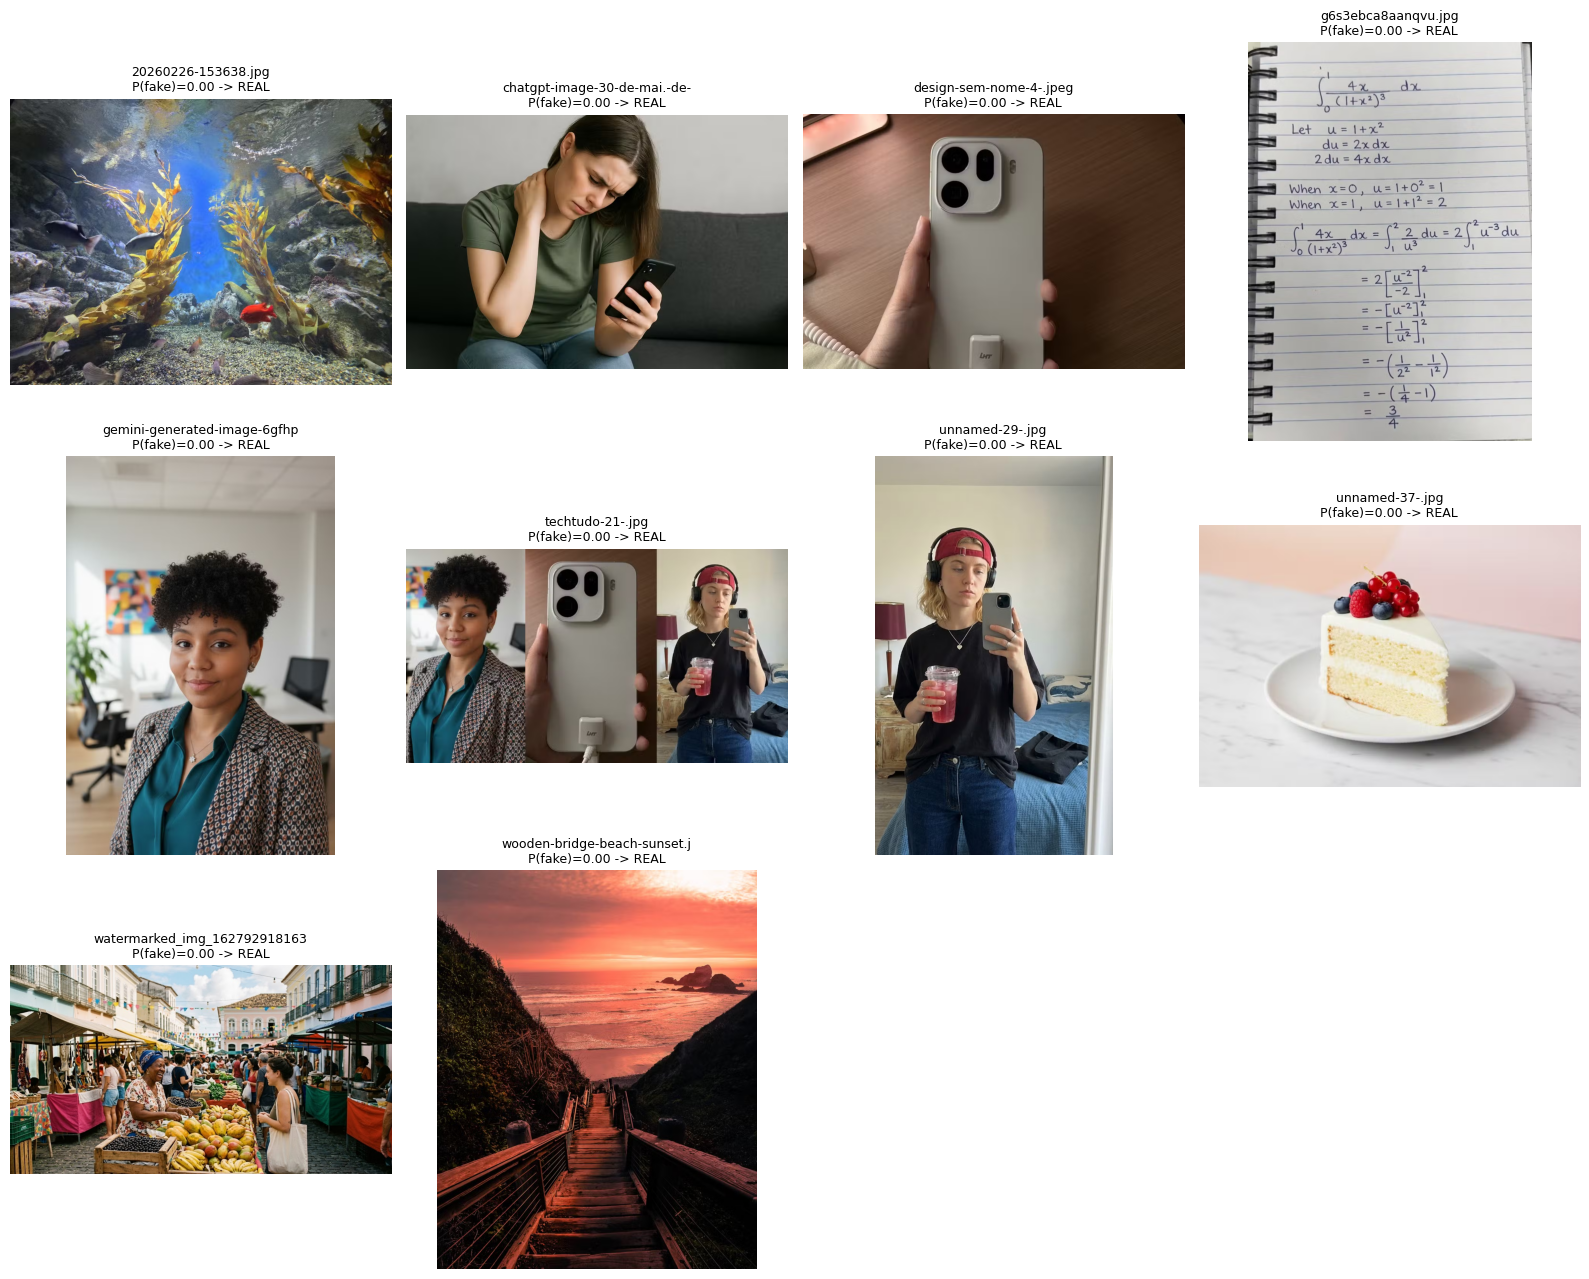

In [13]:
# ---------- Teste rápido com imagens suas ----------
PASTA_DRIVE = "/content/drive/MyDrive/TCC_Final/minhas_imagens"  # ex.: "/content/drive/MyDrive/TCC_Final/minhas_imagens"; None = abre o upload

if PASTA_DRIVE:
    paths = sorted(os.path.join(PASTA_DRIVE, f) for f in os.listdir(PASTA_DRIVE) if f.lower().endswith(EXTS))
else:
    from google.colab import files as colab_files
    up = colab_files.upload()                           # envia as imagens para /content
    paths = [n for n in up if n.lower().endswith(EXTS)]

paths, pils = load_images(paths)
p_fake, gate_w = predict_pil(pils)

# Tabela
print(f"{'arquivo':40s}{'P(fake)':>9s}  decisão" + ("".join(f"{'gate_' + n:>10s}" for n in model.names) if gate_w is not None else ""))
for i, p in enumerate(paths):
    dec = "FAKE" if p_fake[i] >= THR else "REAL"
    gtxt = "".join(f"{v:10.2f}" for v in gate_w[i]) if gate_w is not None else ""
    print(f"{os.path.basename(p)[:39]:40s}{p_fake[i]:9.3f}  {dec:5s}{gtxt}")

# Grade visual
cols = 4
rows = max(1, math.ceil(len(pils) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4.3 * rows), squeeze=False)
for ax in axes.ravel():
    ax.axis("off")                                      # esconde eixos (inclusive os vazios)
for ax, p, im, pf in zip(axes.ravel(), paths, pils, p_fake):
    ax.imshow(im.convert("RGB"))
    ax.set_title(f"{os.path.basename(p)[:28]}\nP(fake)={pf:.2f} -> {'FAKE' if pf >= THR else 'REAL'}", fontsize=9)
plt.tight_layout(); plt.show()

In [14]:
# ---------- Avaliação externa rotulada ----------
# Estrutura esperada:
#
# teste_externo/
# ├── real/
# │   ├── imagem1.jpg
# │   ├── imagem2.png
# │   └── ...
# └── fake/
#     ├── imagem1.jpg
#     ├── imagem2.png
#     └── ...
#
# real = 0
# fake = 1

from pathlib import Path

# Pasta principal do teste externo
EXT_DIR = Path("/content/drive/MyDrive/TCC_Final/teste_externo")

# Extensões aceitas
EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

# ---------------------------------------------------------
# 1. Verifica a estrutura das pastas
# ---------------------------------------------------------

if not EXT_DIR.exists():
    raise FileNotFoundError(
        f"A pasta do teste externo não existe:\n{EXT_DIR}"
    )

if not EXT_DIR.is_dir():
    raise NotADirectoryError(
        f"O caminho do teste externo não é uma pasta:\n{EXT_DIR}"
    )

print("Pasta do teste externo:")
print(EXT_DIR)

# ---------------------------------------------------------
# 2. Localiza imagens de REAL e FAKE
# ---------------------------------------------------------

paths = []
labels = []

for label, class_name in ((0, "real"), (1, "fake")):

    class_dir = EXT_DIR / class_name

    if not class_dir.is_dir():
        raise FileNotFoundError(
            f"A pasta da classe '{class_name}' não foi encontrada:\n"
            f"{class_dir}\n\n"
            f"A estrutura esperada é:\n"
            f"{EXT_DIR}/real\n"
            f"{EXT_DIR}/fake"
        )

    # rglob permite imagens dentro de subpastas
    class_images = sorted(
        p for p in class_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in EXTS
    )

    print(
        f"{class_name.upper():5s}: "
        f"{len(class_images)} imagens encontradas"
    )

    for p in class_images:
        paths.append(str(p))
        labels.append(label)

# ---------------------------------------------------------
# 3. Validação do conjunto encontrado
# ---------------------------------------------------------

if not paths:
    raise ValueError(
        "Nenhuma imagem foi encontrada no conjunto externo.\n\n"
        f"Local pesquisado:\n{EXT_DIR}\n\n"
        f"Extensões aceitas: {EXTS}"
    )

if labels.count(0) == 0:
    raise ValueError(
        "Nenhuma imagem REAL foi encontrada."
    )

if labels.count(1) == 0:
    raise ValueError(
        "Nenhuma imagem FAKE foi encontrada."
    )

print()
print("========== CONJUNTO EXTERNO ==========")
print(f"Total: {len(paths)}")
print(f"Real : {labels.count(0)}")
print(f"Fake : {labels.count(1)}")

# ---------------------------------------------------------
# 4. Predição em blocos
# ---------------------------------------------------------

y = []
p_all = []
kept = []

BATCH_SIZE = 256

for i in range(0, len(paths), BATCH_SIZE):

    batch_paths = paths[i:i + BATCH_SIZE]
    batch_labels = labels[i:i + BATCH_SIZE]

    ok, pils = load_images(batch_paths)

    if not ok:
        continue

    lab_map = dict(zip(batch_paths, batch_labels))

    p, _ = predict_pil(pils)

    p_all.append(np.asarray(p))
    kept.extend(ok)

    y.extend(
        lab_map[path]
        for path in ok
    )

# ---------------------------------------------------------
# 5. Verifica se alguma imagem foi realmente processada
# ---------------------------------------------------------

if not p_all:
    raise ValueError(
        "As imagens foram encontradas, mas nenhuma pôde ser "
        "carregada/processada por load_images()."
    )

y = np.asarray(y)
p_all = np.concatenate(p_all)

if len(y) != len(p_all):
    raise RuntimeError(
        f"Inconsistência entre labels e predições: "
        f"{len(y)} labels para {len(p_all)} predições."
    )

print()
print("========== PREDIÇÃO ==========")
print(f"Imagens processadas: {len(y)}")
print(f"Reais: {(y == 0).sum()}")
print(f"Fakes: {(y == 1).sum()}")

# ---------------------------------------------------------
# 6. Métricas
# ---------------------------------------------------------

def metrics(y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    precision = tp / max(1, tp + fp)
    recall = tp / max(1, tp + fn)

    return {
        "accuracy": (tp + tn) / len(y_true),
        "precision": precision,
        "recall": recall,
        "f1": (
            2 * precision * recall /
            max(1e-12, precision + recall)
        ),
        "tnr": tn / max(1, tn + fp),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }


pred_05 = (p_all >= 0.5).astype(int)
pred_thr = (p_all >= THR).astype(int)

r05 = metrics(y, pred_05)
rthr = metrics(y, pred_thr)

# ---------------------------------------------------------
# 7. Resultados
# ---------------------------------------------------------

if len(np.unique(y)) == 2:
    auc = roc_auc_score(y, p_all)
    print(f"AUC: {auc:.4f}")

print()
print(f"{'':12s}{'@0.5':>10s}{'@limiar':>10s}")

for k in (
    "accuracy",
    "precision",
    "recall",
    "f1",
    "tnr"
):
    print(
        f"{k:12s}"
        f"{r05[k]:10.4f}"
        f"{rthr[k]:10.4f}"
    )

print()
print(
    f"Confusão @limiar: "
    f"TN={rthr['tn']} "
    f"FP={rthr['fp']} "
    f"FN={rthr['fn']} "
    f"TP={rthr['tp']}"
)

# ---------------------------------------------------------
# 8. Salva predição individual de cada imagem
# ---------------------------------------------------------

out_csv = EXT_DIR / "external_predictions.csv"

with open(out_csv, "w", newline="") as f:

    writer = csv.writer(f)

    writer.writerow([
        "path",
        "label",
        "prob_fake",
        "pred_thr"
    ])

    for path, label, prob in zip(
        kept,
        y,
        p_all
    ):
        writer.writerow([
            path,
            int(label),
            f"{prob:.6f}",
            int(prob >= THR)
        ])

print()
print("Arquivo salvo em:")
print(out_csv)

Pasta do teste externo:
/content/drive/MyDrive/TCC_Final/teste_externo
REAL : 8 imagens encontradas
FAKE : 12 imagens encontradas

========== CONJUNTO EXTERNO ==========
Total: 20
Real : 8
Fake : 12

========== PREDIÇÃO ==========
Imagens processadas: 20
Reais: 8
Fakes: 12
AUC: 0.6979

                  @0.5   @limiar
accuracy        0.4000    0.4000
precision       0.0000    0.0000
recall          0.0000    0.0000
f1              0.0000    0.0000
tnr             1.0000    1.0000

Confusão @limiar: TN=8 FP=0 FN=12 TP=0

Arquivo salvo em:
/content/drive/MyDrive/TCC_Final/teste_externo/external_predictions.csv


In [15]:
import os
from google.colab import drive
drive.mount('/content/drive')

PASTA = "/content/drive/MyDrive/"

print("Pasta existe?", os.path.exists(PASTA))

if os.path.exists(PASTA):
    print("\nConteúdo:")
    for nome in os.listdir(PASTA):
        print(nome)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Pasta existe? True

Conteúdo:
Getting started.pdf
Diagrama de Classe PI.txt
Colab Notebooks
Copy of Queer.2024.1080p.WEBRip.10Bit.DDP5.1.x265-Asiimov.srt
Copy of Yellowjackets S03E02 Yellowjackets Dislocation 1080p AMZN WEB-DL DDP5 1 H 264-NTb.mkv
Copy of EP05
pics
IMG_5325 (2).MOV
IMG_5323.MOV
IMG_5332.MOV
IMG_5333.MOV
IMG_5324.MOV
IMG_5322.MOV
IMG_5326.MOV
IMG_5327.MOV
IMG_5328.MOV
IMG_5329.MOV
IMG_5325 (1).MOV
IMG_5331.MOV
IMG_5330.MOV
IMG_5334.MOV
IMG_5325.MOV
lolla
Beatriz Neves CV_AD.pdf
CV_AD.pdf
TCC_Final


In [16]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
# =========================================================
# AVALIAÇÃO EXTERNA — COM RESULTADO INDIVIDUAL
# =========================================================

from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, roc_auc_score

# ---------------------------------------------------------
# Verifica dependências
# ---------------------------------------------------------

if "load_images" not in globals():
    raise RuntimeError(
        "load_images() não está definida. "
        "Execute primeiro a célula que define predict_pil() e load_images()."
    )

if "predict_pil" not in globals():
    raise RuntimeError(
        "predict_pil() não está definida. "
        "Execute primeiro a célula que define predict_pil() e load_images()."
    )

if "THR" not in globals():
    raise RuntimeError(
        "THR não está definido. "
        "Execute primeiro a célula que carrega o checkpoint."
    )

# ---------------------------------------------------------
# Configuração
# ---------------------------------------------------------

EXT_DIR = Path("/content/drive/MyDrive/TCC_Final/teste_externo")
EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

if not EXT_DIR.is_dir():
    raise FileNotFoundError(
        f"Pasta não encontrada:\n{EXT_DIR}"
    )

paths = []
labels = []

# real = 0 | fake = 1
for label, class_name in ((0, "real"), (1, "fake")):

    class_dir = EXT_DIR / class_name

    if not class_dir.is_dir():
        raise FileNotFoundError(
            f"Pasta não encontrada:\n{class_dir}"
        )

    class_images = sorted(
        p for p in class_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in EXTS
    )

    print(
        f"{class_name.upper():5s}: "
        f"{len(class_images)} imagens encontradas"
    )

    for p in class_images:
        paths.append(str(p))
        labels.append(label)

if not paths:
    raise ValueError("Nenhuma imagem encontrada.")

print()
print("========== CONJUNTO EXTERNO ==========")
print(f"Total: {len(paths)}")
print(f"Real : {labels.count(0)}")
print(f"Fake : {labels.count(1)}")

# ---------------------------------------------------------
# Predição
# ---------------------------------------------------------

y = []
p_all = []
kept = []

BATCH_SIZE = 32

for i in range(0, len(paths), BATCH_SIZE):

    batch_paths = paths[i:i + BATCH_SIZE]
    batch_labels = labels[i:i + BATCH_SIZE]

    ok, pils = load_images(batch_paths)

    if not ok:
        continue

    label_map = dict(zip(batch_paths, batch_labels))

    probs, _ = predict_pil(pils)

    p_all.extend(probs)
    kept.extend(ok)

    y.extend(
        label_map[p]
        for p in ok
    )

y = np.asarray(y)
p_all = np.asarray(p_all)

if len(y) == 0:
    raise ValueError(
        "Nenhuma imagem pôde ser carregada/processada."
    )

if len(y) != len(p_all):
    raise RuntimeError(
        f"{len(y)} labels / {len(p_all)} predições."
    )

# ---------------------------------------------------------
# Resultado individual
# ---------------------------------------------------------

resultado = pd.DataFrame({
    "arquivo": [Path(p).name for p in kept],
    "classe_real": np.where(
        y == 1,
        "FAKE",
        "REAL"
    ),
    "prob_fake": p_all
})

resultado["pred_0.50"] = np.where(
    resultado["prob_fake"] >= 0.50,
    "FAKE",
    "REAL"
)

resultado["pred_limiar"] = np.where(
    resultado["prob_fake"] >= THR,
    "FAKE",
    "REAL"
)

resultado = resultado.sort_values(
    "prob_fake",
    ascending=False
)

print()
print("========== RESULTADO INDIVIDUAL ==========")
print(resultado.to_string(index=False))

# ---------------------------------------------------------
# Métricas
# ---------------------------------------------------------

def calcular_metricas(y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    precision = tp / max(1, tp + fp)
    recall = tp / max(1, tp + fn)

    f1 = (
        2 * precision * recall /
        max(1e-12, precision + recall)
    )

    return {
        "accuracy": (tp + tn) / len(y_true),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "tnr": tn / max(1, tn + fp),
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    }

pred_05 = (p_all >= 0.50).astype(int)
pred_thr = (p_all >= THR).astype(int)

r05 = calcular_metricas(y, pred_05)
rthr = calcular_metricas(y, pred_thr)

auc = roc_auc_score(y, p_all)

print()
print("========== RESUMO ==========")
print(f"Imagens processadas: {len(y)}")
print(f"AUC:             {auc:.4f}")
print(f"Limiar salvo:    {THR:.4f}")

if "T" in globals():
    print(f"Temperatura:     {T:.4f}")

print()
print(f"{'':12s}{'@0.50':>10s}{'@limiar':>10s}")

for k in (
    "accuracy",
    "precision",
    "recall",
    "f1",
    "tnr"
):
    print(
        f"{k:12s}"
        f"{r05[k]:10.4f}"
        f"{rthr[k]:10.4f}"
    )

print()
print(
    f"Confusão @0.50: "
    f"TN={r05['tn']} "
    f"FP={r05['fp']} "
    f"FN={r05['fn']} "
    f"TP={r05['tp']}"
)

print(
    f"Confusão @limiar: "
    f"TN={rthr['tn']} "
    f"FP={rthr['fp']} "
    f"FN={rthr['fn']} "
    f"TP={rthr['tp']}"
)

# ---------------------------------------------------------
# Salva CSV
# ---------------------------------------------------------

out_csv = EXT_DIR / "external_predictions.csv"

resultado.to_csv(
    out_csv,
    index=False
)

print()
print("CSV salvo em:")
print(out_csv)

# ---------------------------------------------------------
# Confirma que realmente foi salvo
# ---------------------------------------------------------

if not out_csv.exists():
    raise RuntimeError(
        "O CSV deveria ter sido criado, mas não foi encontrado."
    )

print(f"Tamanho do CSV: {out_csv.stat().st_size} bytes")

REAL : 8 imagens encontradas
FAKE : 12 imagens encontradas

========== CONJUNTO EXTERNO ==========
Total: 20
Real : 8
Fake : 12

========== RESULTADO INDIVIDUAL ==========
                                       arquivo classe_real  prob_fake pred_0.50 pred_limiar
                              techtudo-21-.jpg        FAKE   0.000550      REAL        REAL
                               unnamed-37-.jpg        FAKE   0.000549      REAL        REAL
   gemini-generated-image-6gfhpd6gfhpd6gfh.jpg        FAKE   0.000546      REAL        REAL
                wooden-bridge-beach-sunset.jpg        REAL   0.000545      REAL        REAL
    WhatsApp Image 2026-10-07 at 11.43.08.jpeg        FAKE   0.000533      REAL        REAL
    WhatsApp Image 2026-10-07 at 11.43.11.jpeg        REAL   0.000531      REAL        REAL
                               unnamed-29-.jpg        FAKE   0.000527      REAL        REAL
WhatsApp Image 2026-10-07 at 11.43.07 (1).jpeg        FAKE   0.000526      REAL        REAL
